# Monitoring the model in production: drift scenarios

**Objective:** a model that is deployed does not stay good forever. Here we call the API like a client system would do, with three batches of new clients, and we look at the drift report (PSI of each variable and of the score) that the API returns:

1. new clients similar to the training ones
2. a new commercial campaign for young clients with low limits
3. an economic shock: more clients start to pay late

Before running this notebook: `python -m creditapi.train`. The notebook uses the FastAPI `TestClient`, so the API does not need to be running.

## Part 1. Libraries and API

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from fastapi.testclient import TestClient

from creditapi.app import app
from creditapi.train import load_data

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
api = TestClient(app)
print(api.get("/health").json())
api.get("/model-info").json()

C:\Users\lezqu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


C:\Users\lezqu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/22 15:32:12 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\lezqu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


{'status': 'ok', 'model_loaded': True}


{'model': 'HistGradientBoostingClassifier',
 'version': '99272324',
 'trained_at': '2026-10-22T20:32:02+00:00',
 'features': ['LIMIT_BAL',
  'AGE',
  'PAY_1',
  'PAY_2',
  'PAY_3',
  'BILL_AMT1',
  'PAY_AMT1',
  'PAY_AMT2',
  'utilisation',
  'months_late',
  'max_delay'],
 'metrics_test': {'auc': 0.7761,
  'gini': 0.5522,
  'brier': 0.1358,
  'default_rate_test': 0.2212},
 'training_rows': 22500,
 'intended_use': 'Probability of default next month for credit card clients',
 'limitations': 'Trained on one portfolio (Taiwan, 2005); must be recalibrated before use on another population'}

## Part 2. Three batches of new clients

In [2]:
df = load_data()
campos = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6", "BILL_AMT1", "PAY_AMT1", "PAY_AMT2"]
base = df[campos].sample(2000, random_state=1)

# 2. young clients with low limits
jovenes = df[(df["AGE"] < 30) & (df["LIMIT_BAL"] <= 100000)][campos].sample(2000, random_state=2, replace=True)

# 3. economic shock: 25% of the clients who paid on time start to be 1-2 months late
choque = base.copy()
rng = np.random.default_rng(3)
afectados = rng.random(len(choque)) < 0.25
for c in ["PAY_1", "PAY_2"]:
    choque.loc[afectados & (choque[c] <= 0), c] = rng.integers(1, 3, size=(afectados & (choque[c] <= 0)).sum())

lotes = {"similar clients": base, "young clients, low limits": jovenes, "economic shock": choque}

## Part 3. Scoring the batches and reading the drift report

In [3]:
reportes, resumen = {}, []
for nombre, lote in lotes.items():
    r = api.post("/predict-batch", json={"clients": lote.astype(float).astype(object).to_dict(orient="records")})
    body = r.json()
    rep = pd.DataFrame(body["drift"])
    reportes[nombre] = rep
    resumen.append({"batch": nombre, "mean_pd": body["mean_pd"], "psi_score": rep.loc[rep["variable"] == "_score", "psi"].iloc[0],
                    "variables_shifted": int((rep["status"] == "shift").sum()), "variables_watch": int((rep["status"] == "watch").sum())})
pd.DataFrame(resumen).round(3)

,batch,mean_pd,psi_score,variables_shifted,variables_watch
0,similar clients,0.221,0.005,0,0
1,"young clients, low limits",0.284,0.330,6,4
2,economic shock,0.286,0.107,0,5


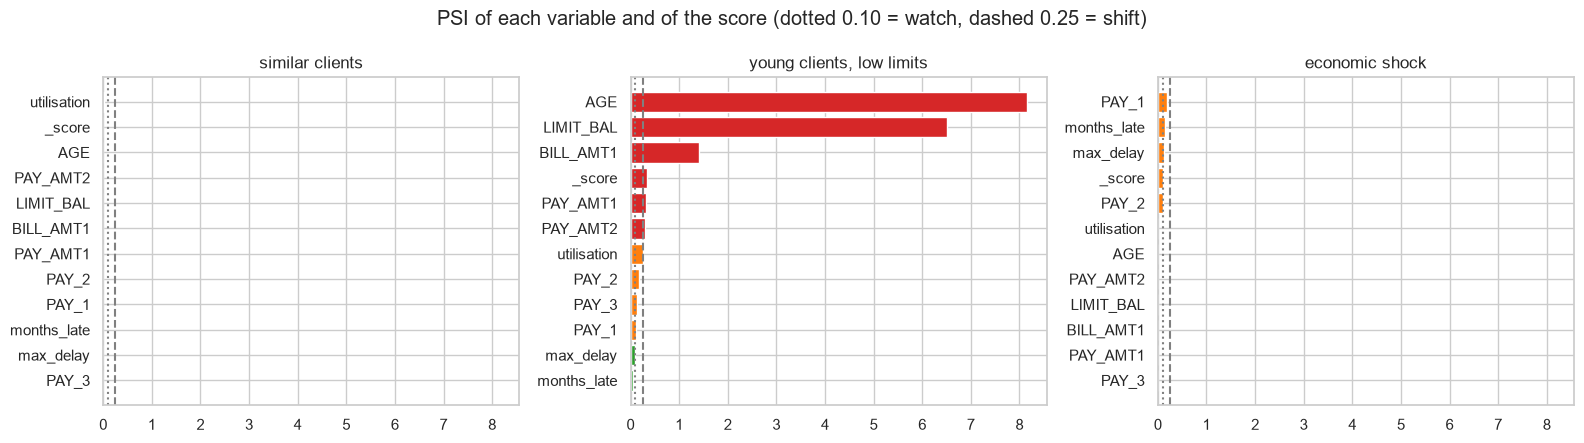

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
for ax, (nombre, rep) in zip(axes, reportes.items()):
    colores = rep["status"].map({"stable": "tab:green", "watch": "tab:orange", "shift": "tab:red"})
    ax.barh(rep["variable"], rep["psi"], color=colores)
    ax.axvline(0.10, color="grey", ls=":")
    ax.axvline(0.25, color="grey", ls="--")
    ax.set_title(nombre)
    ax.invert_yaxis()
plt.suptitle("PSI of each variable and of the score (dotted 0.10 = watch, dashed 0.25 = shift)")
plt.tight_layout()
plt.savefig("figures/drift_scenarios.png", bbox_inches="tight")
plt.show()

In [5]:
for nombre, rep in reportes.items():
    print(nombre)
    print(rep.head(4).round(3).to_string(index=False), "\n")

similar clients
   variable   psi status
utilisation 0.007 stable
     _score 0.005 stable
        AGE 0.005 stable
   PAY_AMT2 0.004 stable 

young clients, low limits
 variable   psi status
      AGE 8.151  shift
LIMIT_BAL 6.505  shift
BILL_AMT1 1.407  shift
   _score 0.330  shift 

economic shock
   variable   psi status
      PAY_1 0.186  watch
months_late 0.142  watch
  max_delay 0.126  watch
     _score 0.107  watch 



## Conclusions

- With clients similar to the training ones, all the PSI are below 0.01: the model can be used as it is.
- The campaign of young clients with low limits changes the population completely (PSI of age, limit and bill far above 0.25) and also the score (PSI 0.33, mean PD from 22% to 28%). The report raises the alarm before we have any default to measure: the model was trained on another mix of clients, so it should be validated for this segment.
- The economic shock moves the payment variables and the score into the "watch" zone (PSI 0.11 to 0.19) and the mean PD goes from 22% to 29%. Here the model is doing its job (the clients are riskier), but the report tells the risk team that the portfolio changed and that provisions and limits must be reviewed.
- The first version of my PSI assumed 10% of the training data in each decile. For discrete variables (months late) many deciles are the same number, and that gave false alarms on stable data. Now the reference stores the real share of each bin, and there is a test for it.